In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import re
import string

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [3]:
df = pd.read_csv("spam.csv", encoding="latin-1")

In [4]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [5]:
print("Dataset Shape:", df.shape)

Dataset Shape: (5572, 5)


In [6]:
print(df.columns)

Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='str')


In [8]:

df = df.rename(columns={
    'v1': 'label',
    'v2': 'message'
})


In [9]:
df.head()

,label,message,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [10]:
print(df.isnull().sum())

label            0
message          0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64


In [11]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 403


In [12]:
df = df.drop_duplicates()

In [13]:
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (5169, 5)


In [14]:
print(df['label'].value_counts())

label
ham     4516
spam     653
Name: count, dtype: int64


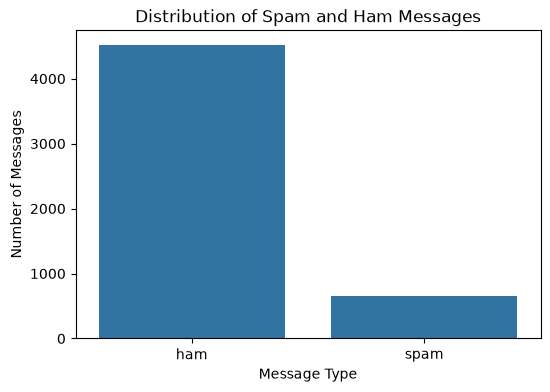

In [15]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='label')

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")

plt.show()

In [16]:
df['label_encoded'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

In [17]:
df.head()

,label,message,Unnamed: 2,Unnamed: 3,Unnamed: 4,label_encoded
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN,0
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN,1
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN,0


In [18]:
def clean_text(text):
    
    text = text.lower()
    
    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    
    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    
    # Remove numbers
    text = re.sub(r'\d+', '', text)
    
    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

In [19]:
df['clean_message'] = df['message'].apply(clean_text)

In [20]:
df[['message', 'clean_message']].head()

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


In [21]:
spam_text = " ".join(
    df[df['label'] == 'spam']['clean_message']
)

In [27]:
wordcloud_spam = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(spam_text)

In [26]:
from wordcloud import WordCloud

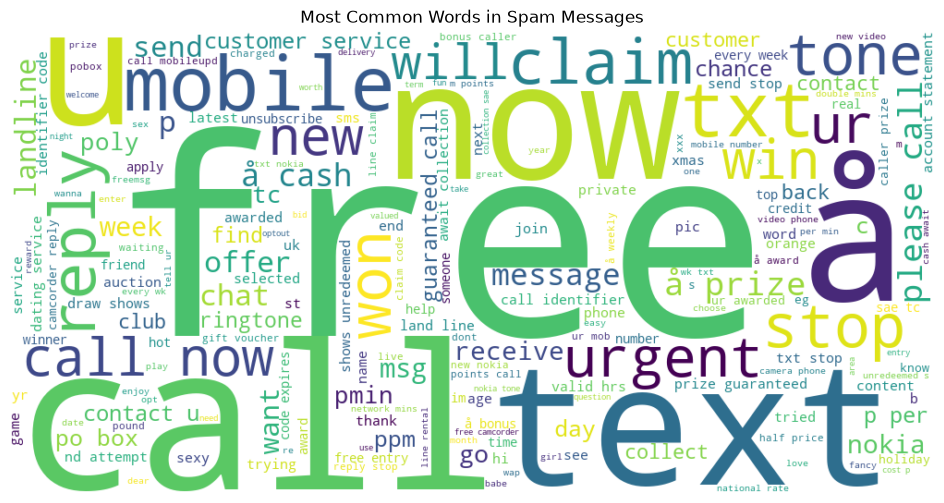

In [28]:
plt.figure(figsize=(12,6))

plt.imshow(wordcloud_spam, interpolation='bilinear')

plt.axis('off')

plt.title("Most Common Words in Spam Messages")

plt.show()

In [29]:
ham_text = " ".join(
    df[df['label'] == 'ham']['clean_message']
)

In [30]:
wordcloud_ham = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(ham_text)

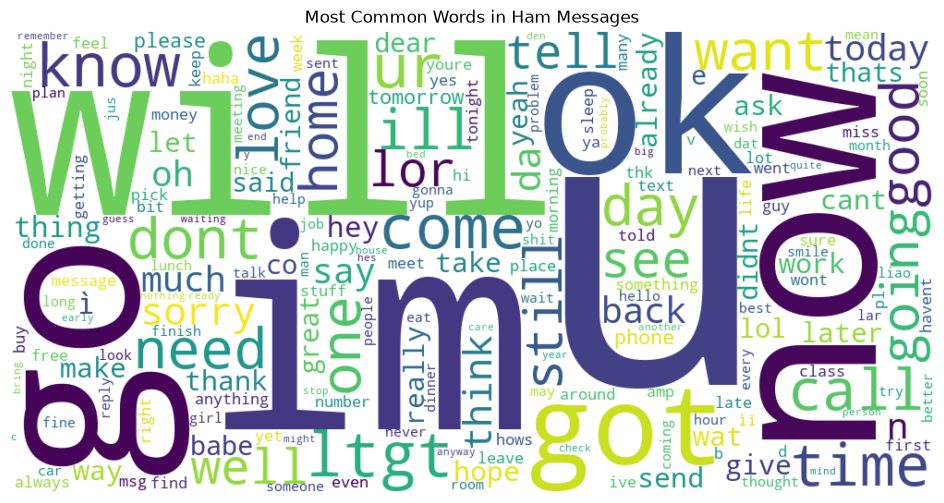

In [31]:
plt.figure(figsize=(12,6))

plt.imshow(wordcloud_ham, interpolation='bilinear')

plt.axis('off')

plt.title("Most Common Words in Ham Messages")

plt.show()

In [32]:
X = df['clean_message']
y = df['label_encoded']

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [34]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4135
Testing samples: 1034


In [35]:
count_vectorizer = CountVectorizer(
    stop_words='english'
)

In [36]:
X_train_count = count_vectorizer.fit_transform(X_train)

In [37]:
X_test_count = count_vectorizer.transform(X_test)

In [38]:
print("Training matrix:", X_train_count.shape)
print("Testing matrix:", X_test_count.shape)

Training matrix: (4135, 7095)
Testing matrix: (1034, 7095)


In [39]:
print(count_vectorizer.vocabulary_)

{'cool': 1244, 'come': 1141, 'havent': 2610, 'wined': 6835, 'dined': 1585, 'huh': 2808, 'late': 3303, 'fr': 2198, 'dinner': 1589, 'exwife': 1966, 'able': 15, 'kids': 3200, 'want': 6688, 'day': 1423, 'hope': 2757, 'ur': 6523, 'head': 2618, 'doesnt': 1645, 'hurt': 2828, 'ploughing': 4566, 'way': 6721, 'pile': 4525, 'ironing': 2997, 'staying': 5776, 'chinky': 1033, 'tonight': 6285, 'round': 5144, 'like': 3397, 'ryder': 5180, 'unsoldnow': 6498, 'gibbs': 2366, 'guess': 2525, 'pub': 4800, 'im': 2876, 'happy': 2589, 'pig': 4523, 'clover': 1094, 'saying': 5237, 'ok': 4230, 'set': 5341, 'let': 3366, 'noe': 4101, 'details': 1530, 'later': 3307, 'lar': 3296, 'going': 2415, 'home': 2736, 'bring': 729, 'tat': 6026, 'cd': 924, 'don': 1667, 'forget': 2173, 'stop': 5811, 'calling': 832, 'cancer': 858, 'throat': 6191, 'hurts': 2830, 'talk': 6012, 'answering': 242, 'everyones': 1911, 'calls': 841, 'babysitting': 440, 'monday': 3872, 'telling': 6072, 'tell': 6071, 'treat': 6353, 'hi': 2679, 'realise': 49

In [40]:
print(
    list(count_vectorizer.vocabulary_.keys())[:20]
)

['cool', 'come', 'havent', 'wined', 'dined', 'huh', 'late', 'fr', 'dinner', 'exwife', 'able', 'kids', 'want', 'day', 'hope', 'ur', 'head', 'doesnt', 'hurt', 'ploughing']


In [41]:
lr_count = LogisticRegression(
    max_iter=1000
)

lr_count.fit(
    X_train_count,
    y_train
)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [42]:
lr_count_pred = lr_count.predict(X_test_count)

In [43]:
lr_count_accuracy = accuracy_score(
    y_test,
    lr_count_pred
)

print("Logistic Regression Accuracy:", lr_count_accuracy)

Logistic Regression Accuracy: 0.9738878143133463


In [44]:
print(
    classification_report(
        y_test,
        lr_count_pred,
        target_names=['Ham', 'Spam']
    )
)

              precision    recall  f1-score   support

         Ham       0.97      1.00      0.99       903
        Spam       1.00      0.79      0.89       131

    accuracy                           0.97      1034
   macro avg       0.99      0.90      0.94      1034
weighted avg       0.97      0.97      0.97      1034



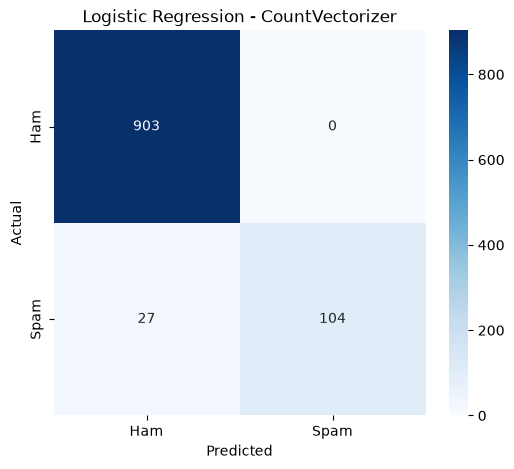

In [45]:
cm = confusion_matrix(
    y_test,
    lr_count_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - CountVectorizer")

plt.show()

In [46]:
tfidf_vectorizer = TfidfVectorizer(
    stop_words='english'
)

In [50]:
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

In [51]:
print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (4135, 7095)
Testing matrix: (1034, 7095)


In [52]:

lr_tfidf = LogisticRegression(
    max_iter=1000
)

lr_tfidf.fit(
    X_train_tfidf,
    y_train
)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [53]:
lr_tfidf_pred = lr_tfidf.predict(X_test_tfidf)

In [54]:
lr_tfidf_accuracy = accuracy_score(
    y_test,
    lr_tfidf_pred
)

print(
    "Logistic Regression TF-IDF Accuracy:",
    lr_tfidf_accuracy
)

Logistic Regression TF-IDF Accuracy: 0.9487427466150871


In [55]:
print(
    classification_report(
        y_test,
        lr_tfidf_pred,
        target_names=['Ham', 'Spam']
    )
)

              precision    recall  f1-score   support

         Ham       0.95      1.00      0.97       903
        Spam       0.99      0.60      0.75       131

    accuracy                           0.95      1034
   macro avg       0.97      0.80      0.86      1034
weighted avg       0.95      0.95      0.94      1034



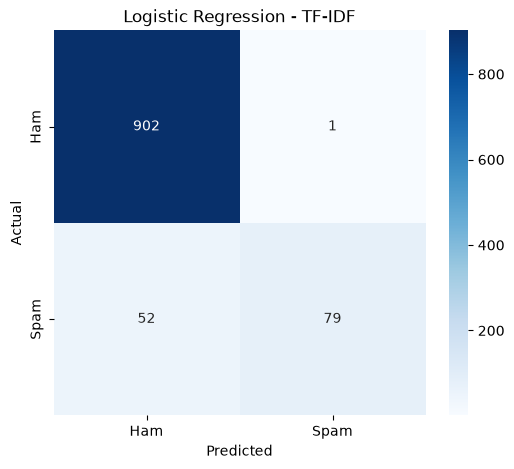

In [56]:
cm = confusion_matrix(
    y_test,
    lr_tfidf_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - TF-IDF")

plt.show()

In [57]:
models_count = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    
    "Naive Bayes": MultinomialNB(),
    
    "Linear SVM": LinearSVC(),
    
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

In [58]:
count_results = []

for name, model in models_count.items():
    
    model.fit(
        X_train_count,
        y_train
    )
    
    predictions = model.predict(
        X_test_count
    )
    
    accuracy = accuracy_score(
        y_test,
        predictions
    )
    
    precision = precision_score(
        y_test,
        predictions
    )
    
    recall = recall_score(
        y_test,
        predictions
    )
    
    f1 = f1_score(
        y_test,
        predictions
    )
    
    count_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

In [65]:
count_results_df = pd.DataFrame(
    count_results
)

print(count_results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.973888   1.000000  0.793893  0.885106
1          Naive Bayes  0.978723   0.936000  0.893130  0.914062
2           Linear SVM  0.978723   0.990991  0.839695  0.909091
3        Decision Tree  0.957447   0.871795  0.778626  0.822581
4        Random Forest  0.971954   0.981132  0.793893  0.877637


In [66]:
count_results_df = pd.DataFrame(
    count_results
)

print(count_results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.973888   1.000000  0.793893  0.885106
1          Naive Bayes  0.978723   0.936000  0.893130  0.914062
2           Linear SVM  0.978723   0.990991  0.839695  0.909091
3        Decision Tree  0.957447   0.871795  0.778626  0.822581
4        Random Forest  0.971954   0.981132  0.793893  0.877637


In [59]:
models_tfidf = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    
    "Naive Bayes": MultinomialNB(),
    
    "Linear SVM": LinearSVC(),
    
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

In [60]:
tfidf_results = []

for name, model in models_tfidf.items():
    
    model.fit(
        X_train_tfidf,
        y_train
    )
    
    predictions = model.predict(
        X_test_tfidf
    )
    
    accuracy = accuracy_score(
        y_test,
        predictions
    )
    
    precision = precision_score(
        y_test,
        predictions
    )
    
    recall = recall_score(
        y_test,
        predictions
    )
    
    f1 = f1_score(
        y_test,
        predictions
    )
    
    tfidf_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

In [61]:
tfidf_results_df = pd.DataFrame(
    tfidf_results
)

tfidf_results_df = tfidf_results_df.sort_values(
    by='Accuracy',
    ascending=False
)

tfidf_results_df

,Model,Accuracy,Precision,Recall,F1 Score
2,Linear SVM,0.980658,0.991150,0.854962,0.918033
4,Random Forest,0.970019,0.990196,0.770992,0.866953
1,Naive Bayes,0.962282,0.989362,0.709924,0.826667
0,Logistic Regression,0.948743,0.987500,0.603053,0.748815
3,Decision Tree,0.947776,0.813008,0.763359,0.787402


In [67]:
count_results_df['Vectorizer'] = 'CountVectorizer'

tfidf_results_df['Vectorizer'] = 'TF-IDF'

In [68]:
comparison_df = pd.concat(
    [
        count_results_df,
        tfidf_results_df
    ],
    ignore_index=True
)

In [69]:
comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,Vectorizer
0,Logistic Regression,0.973888,1.000000,0.793893,0.885106,CountVectorizer
1,Naive Bayes,0.978723,0.936000,0.893130,0.914062,CountVectorizer
2,Linear SVM,0.978723,0.990991,0.839695,0.909091,CountVectorizer
3,Decision Tree,0.957447,0.871795,0.778626,0.822581,CountVectorizer
4,Random Forest,0.971954,0.981132,0.793893,0.877637,CountVectorizer
5,Linear SVM,0.980658,0.991150,0.854962,0.918033,TF-IDF
6,Random Forest,0.970019,0.990196,0.770992,0.866953,TF-IDF
7,Naive Bayes,0.962282,0.989362,0.709924,0.826667,TF-IDF
8,Logistic Regression,0.948743,0.987500,0.603053,0.748815,TF-IDF
9,Decision Tree,0.947776,0.813008,0.763359,0.787402,TF-IDF


In [71]:
comparison_df = comparison_df[
    [
        'Vectorizer',
        'Model',
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score'
    ]
]

comparison_df

,Vectorizer,Model,Accuracy,Precision,Recall,F1 Score
0,CountVectorizer,Logistic Regression,0.973888,1.000000,0.793893,0.885106
1,CountVectorizer,Naive Bayes,0.978723,0.936000,0.893130,0.914062
2,CountVectorizer,Linear SVM,0.978723,0.990991,0.839695,0.909091
3,CountVectorizer,Decision Tree,0.957447,0.871795,0.778626,0.822581
4,CountVectorizer,Random Forest,0.971954,0.981132,0.793893,0.877637
5,TF-IDF,Linear SVM,0.980658,0.991150,0.854962,0.918033
6,TF-IDF,Random Forest,0.970019,0.990196,0.770992,0.866953
7,TF-IDF,Naive Bayes,0.962282,0.989362,0.709924,0.826667
8,TF-IDF,Logistic Regression,0.948743,0.987500,0.603053,0.748815
9,TF-IDF,Decision Tree,0.947776,0.813008,0.763359,0.787402


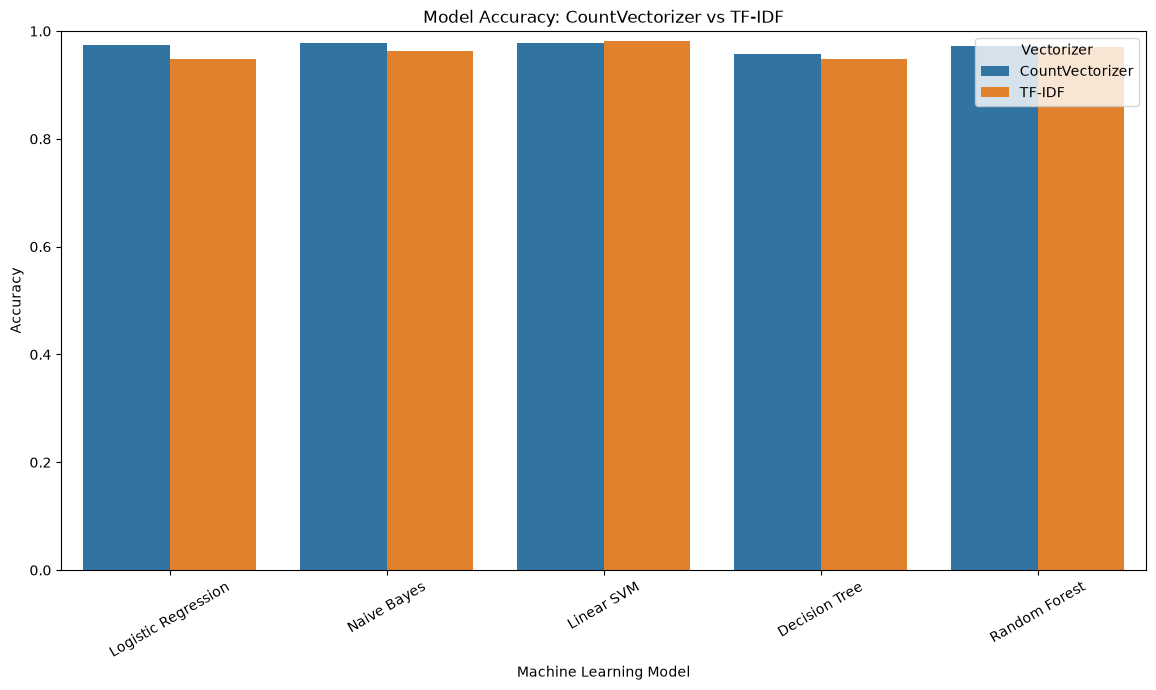

In [72]:
plt.figure(figsize=(14,7))

sns.barplot(
    data=comparison_df,
    x='Model',
    y='Accuracy',
    hue='Vectorizer'
)

plt.title(
    "Model Accuracy: CountVectorizer vs TF-IDF"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")

plt.xticks(rotation=30)

plt.ylim(0, 1)

plt.show()

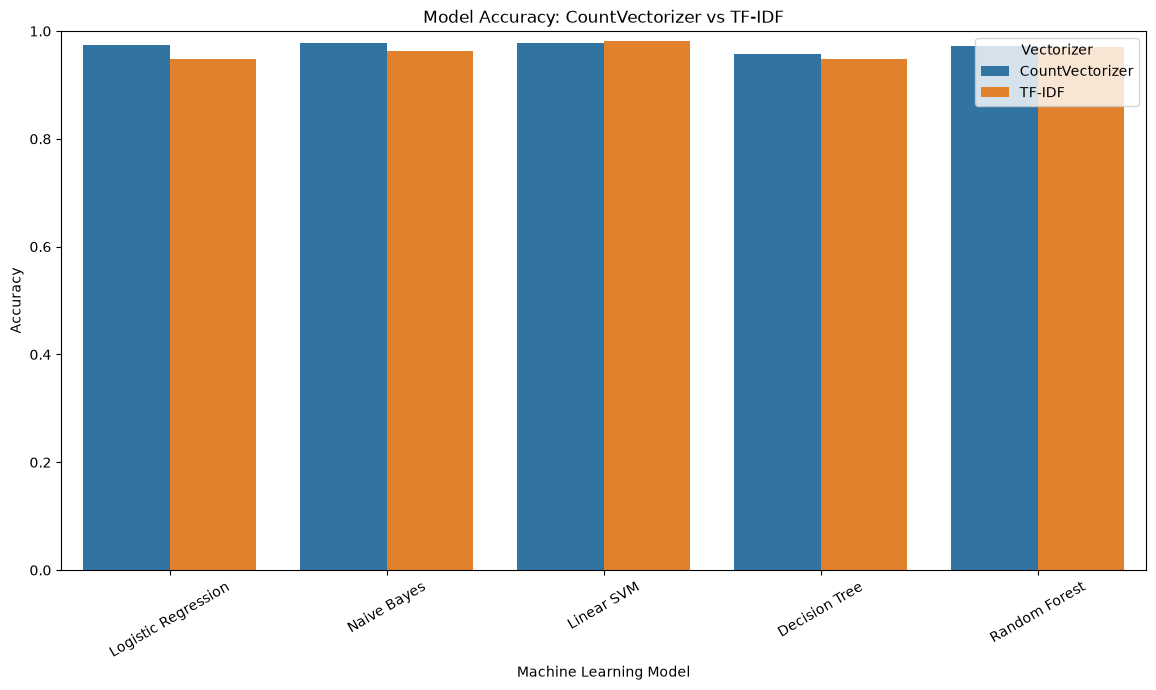

In [73]:
plt.figure(figsize=(14,7))

sns.barplot(
    data=comparison_df,
    x='Model',
    y='Accuracy',
    hue='Vectorizer'
)

plt.title(
    "Model Accuracy: CountVectorizer vs TF-IDF"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")

plt.xticks(rotation=30)

plt.ylim(0, 1)

plt.show()

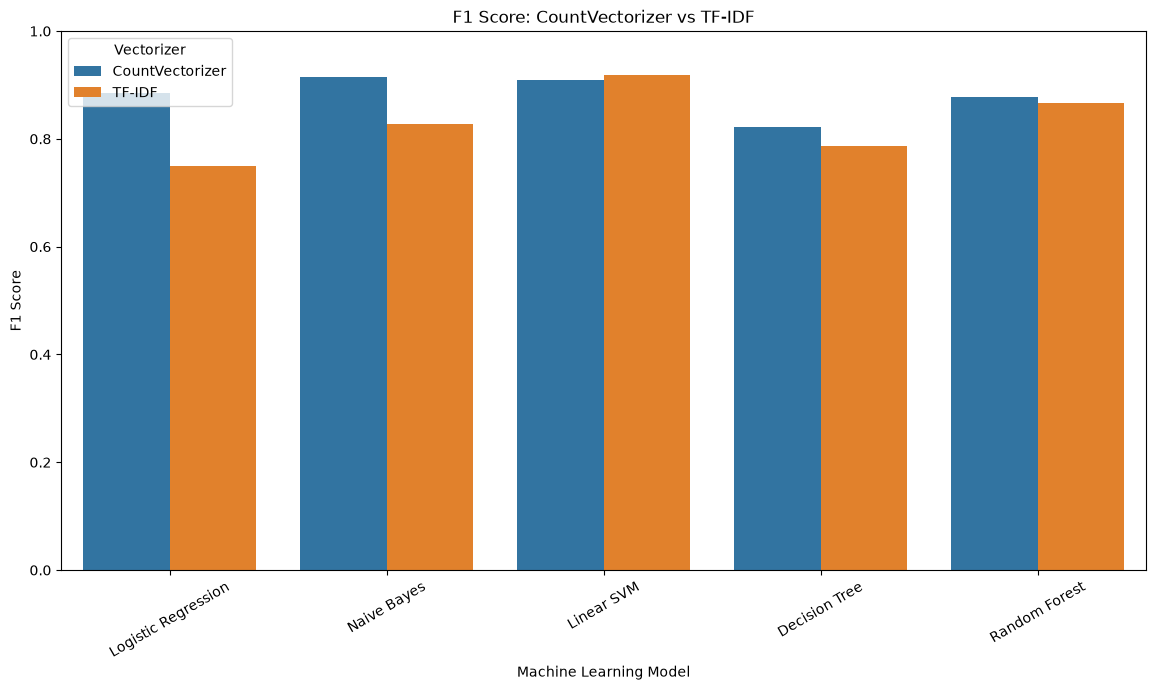

In [74]:
plt.figure(figsize=(14,7))

sns.barplot(
    data=comparison_df,
    x='Model',
    y='F1 Score',
    hue='Vectorizer'
)

plt.title(
    "F1 Score: CountVectorizer vs TF-IDF"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("F1 Score")

plt.xticks(rotation=30)

plt.ylim(0, 1)

plt.show()

In [75]:
final_model = LinearSVC()

final_model.fit(
    X_train_tfidf,
    y_train
)

final_pred = final_model.predict(
    X_test_tfidf
)

In [76]:
print(
    "Final Accuracy:",
    accuracy_score(y_test, final_pred)
)

Final Accuracy: 0.9806576402321083


In [77]:
print(
    "Precision:",
    precision_score(y_test, final_pred)
)

Precision: 0.9911504424778761


In [78]:
print(
    "Precision:",
    precision_score(y_test, final_pred)
)

Precision: 0.9911504424778761


In [79]:
print(
    classification_report(
        y_test,
        final_pred,
        target_names=['Ham', 'Spam']
    )
)

              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       903
        Spam       0.99      0.85      0.92       131

    accuracy                           0.98      1034
   macro avg       0.99      0.93      0.95      1034
weighted avg       0.98      0.98      0.98      1034



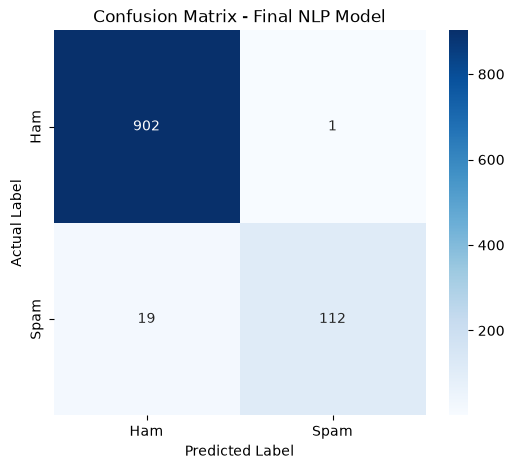

In [80]:
cm = confusion_matrix(
    y_test,
    final_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title(
    "Confusion Matrix - Final NLP Model"
)

plt.show()

In [81]:
final_model = LinearSVC()

final_model.fit(
    X_train_tfidf,
    y_train
)

final_pred = final_model.predict(
    X_test_tfidf
)

In [82]:
print(
    "Final Accuracy:",
    accuracy_score(y_test, final_pred)
)

Final Accuracy: 0.9806576402321083


In [83]:
print(
    classification_report(
        y_test,
        final_pred,
        target_names=['Ham', 'Spam']
    )
)

              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       903
        Spam       0.99      0.85      0.92       131

    accuracy                           0.98      1034
   macro avg       0.99      0.93      0.95      1034
weighted avg       0.98      0.98      0.98      1034



In [84]:
def predict_sms(message):
    
    cleaned = clean_text(message)
    
    transformed = tfidf_vectorizer.transform(
        [cleaned]
    )
    
    prediction = final_model.predict(
        transformed
    )[0]
    
    if prediction == 1:
        return "SPAM"
    else:
        return "HAM"

In [85]:
message1 = "Congratulations! You have won a free prize. Click now to claim."

In [86]:
def predict_sms(message):
    
    cleaned = clean_text(message)
    
    transformed = tfidf_vectorizer.transform(
        [cleaned]
    )
    
    prediction = final_model.predict(
        transformed
    )[0]
    
    if prediction == 1:
        return "SPAM"
    else:
        return "HAM"

In [87]:
 predict_sms(message1)

'SPAM'

In [88]:
message2 = "Hey, are we meeting at college tomorrow?"

In [89]:
print(
    predict_sms(message2)
)

HAM


In [90]:
test_messages = [
    "Congratulations! You won a free lottery prize!",
    "Can you send me the notes from today's class?",
    "URGENT! Claim your cash reward now!",
    "I will call you when I reach home.",
    "You have been selected for a free vacation."
]

In [91]:
for message in test_messages:
    
    result = predict_sms(message)
    
    print("Message:", message)
    print("Prediction:", result)
    print("-" * 60)

Message: Congratulations! You won a free lottery prize!
Prediction: SPAM
------------------------------------------------------------
Message: Can you send me the notes from today's class?
Prediction: HAM
------------------------------------------------------------
Message: URGENT! Claim your cash reward now!
Prediction: SPAM
------------------------------------------------------------
Message: I will call you when I reach home.
Prediction: HAM
------------------------------------------------------------
Message: You have been selected for a free vacation.
Prediction: SPAM
------------------------------------------------------------
